# 2 · The head-to-head comparison: five methods, four budgets

*Part 2 of the story. Previously: `01_setup_and_methods.ipynb`.*

**What this notebook answers.** The task brief asks for a comparison of the base
LLM, text RAG and structured/graph RAG on the same questions, measuring
correctness, citation quality and response time, with retrieval and composition
errors separated. That comparison is this notebook - with the candidate budget
as the axis, because it is the one knob that changes what the methods can do.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elexai.analysis as al

al.scientific_style()
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 220)


run_of = {
    1: al.find_run("cap1"),
    2: al.find_run("cap2"),
    3: al.find_run("cap3"),
    12: al.find_run("skeleton"),
}
caps = [1, 2, 3, 12]
acc = al.accuracy_frame(list(run_of.values()))
acc["cap"] = acc["cap"].astype(int)
answers_by_cap = {cap: al.load_answers(rid) for cap, rid in run_of.items()}
full = answers_by_cap[12]
senses = al.load_senses_table().set_index("sense_id")
questions = al.load_questions_table().set_index("question_id")
metrics_full = al.load_metrics(run_of[12])

## Correctness across budgets

In [2]:
summary = acc[acc["variant"].isin(["B", "C", "D", "oracle"])].pivot_table(
    index="cap", columns="variant", values="citation_accuracy_excl_trick"
).round(3)
summary

variant,B,C,D,oracle
cap,,,,
1,0.294,0.353,0.529,1.0
2,0.294,0.559,0.676,1.0
3,0.294,0.735,0.824,1.0
12,0.294,1.000,1.000,1.0


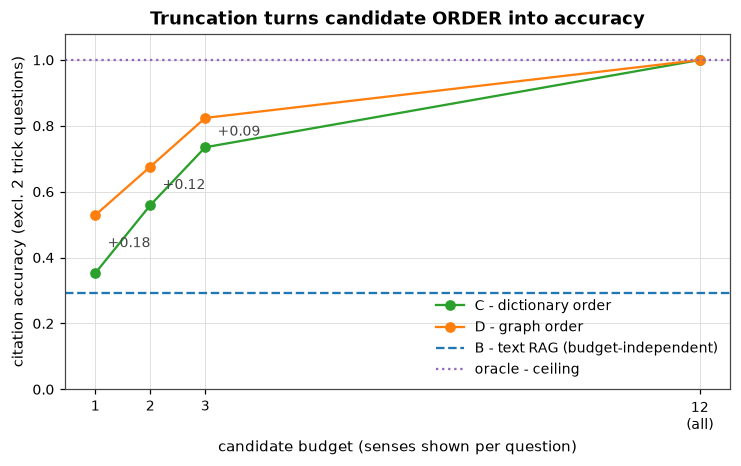

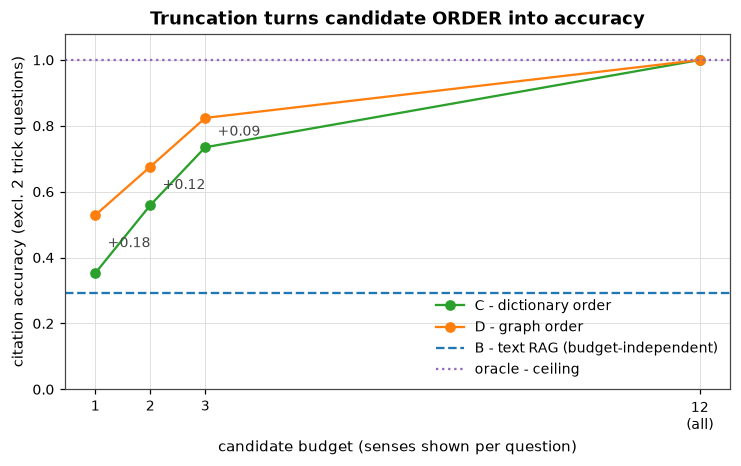

In [3]:
def series(variant, col="citation_accuracy_excl_trick"):
    s = acc[acc["variant"] == variant].set_index("cap")[col]
    return [s[c] for c in caps]

fig, ax = plt.subplots(figsize=(7.8, 4.2))
c_s, d_s = series("C"), series("D")
ax.plot(caps, c_s, "o-", color=al.VARIANT_COLORS["C"], label="C - dictionary order")
ax.plot(caps, d_s, "o-", color=al.VARIANT_COLORS["D"], label="D - graph order")
ax.axhline(series("B")[0], ls="--", color=al.VARIANT_COLORS["B"], label="B - text RAG (budget-independent)")
ax.axhline(series("oracle")[0], ls=":", color=al.VARIANT_COLORS["oracle"], label="oracle - ceiling")
for i, cap in enumerate(caps):
    if d_s[i] > c_s[i] + 1e-9:
        ax.annotate(
            f"+{d_s[i] - c_s[i]:.2f}", (cap, (c_s[i] + d_s[i]) / 2),
            textcoords="offset points", xytext=(8, -2), fontsize=9, color="#444444",
        )
ax.set_xticks(caps, ["1", "2", "3", "12\n(all)"])
ax.set_xlabel("candidate budget (senses shown per question)")
ax.set_ylabel("citation accuracy (excl. 2 trick questions)")
ax.set_ylim(0, 1.08)
ax.set_title("Truncation turns candidate ORDER into accuracy")
ax.legend(loc="lower right")
al.save_figure(fig, "02_budget_curve")
fig

> **Reading the chart.** With everything visible, C and D are identical (100 %).
> As the budget shrinks, both fall - but D falls more slowly:
> **+0.09 at budget 3, +0.12 at budget 2, +0.18 at budget 1**. B is flat (its
> context never changes) and the oracle ceiling stays at 100 %: the drop is
> purely about *which* candidates make it onto the table.

> **Takeaway.** The head-to-head verdict depends on the budget. With a roomy
> context, structure and graph are indistinguishable from each other (and from
> the oracle). With a tight context, the ordering decides - and the graph's
> ordering is better. Notebook 3 turns this into a rule you can check *before*
> building anything.

## Why: under truncation, coverage is accuracy

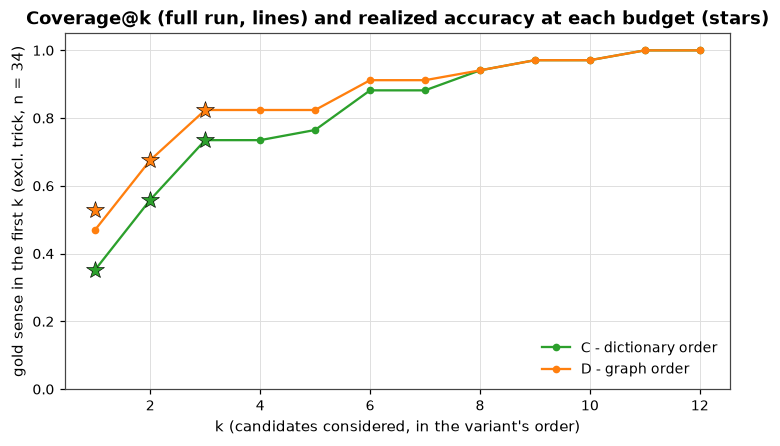

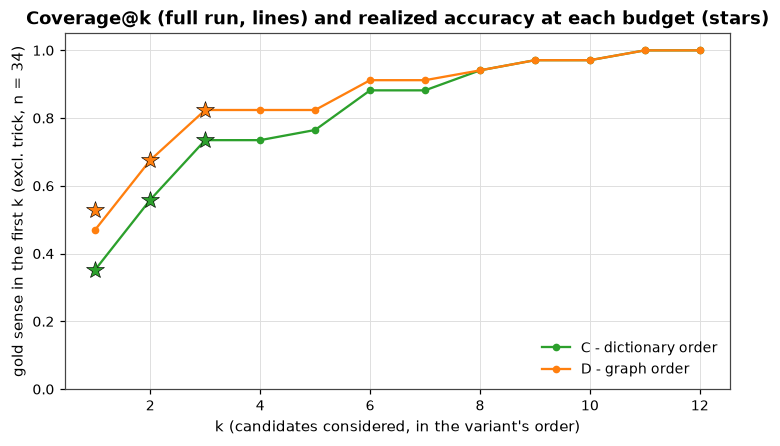

In [4]:
cov = al.coverage_frame([run_of[12]], scope="excl_trick")

fig, ax = plt.subplots(figsize=(7.8, 4.2))
for v, label in [("C", "C - dictionary order"), ("D", "D - graph order")]:
    sub = cov[cov["variant"] == v].sort_values("k")
    ax.plot(sub["k"], sub["coverage"], "o-", ms=4, color=al.VARIANT_COLORS[v], label=label)
for cap in [1, 2, 3]:
    for v in ["C", "D"]:
        val = float(acc[(acc["cap"] == cap) & (acc["variant"] == v)]["citation_accuracy_excl_trick"].iloc[0])
        ax.plot([cap], [val], marker="*", ms=12, color=al.VARIANT_COLORS[v], mec="black", mew=0.4, zorder=5)
ax.set_xlabel("k (candidates considered, in the variant's order)")
ax.set_ylabel("gold sense in the first k (excl. trick, n = 34)")
ax.set_ylim(0, 1.05)
ax.set_title("Coverage@k (full run, lines) and realized accuracy at each budget (stars)")
ax.legend(loc="lower right")
al.save_figure(fig, "02_coverage_curves")
fig

> **Reading the chart.** The lines are the *potential*: how often the gold sense
> sits within the first k candidates under each ordering. D's curve lies above
> C's everywhere. The stars are what actually happened in the budget runs - they
> sit essentially **on the curves**, because composition was error-free once the
> gold was shown (C: 0 composition errors at every budget; D: only the trick
> items). Under truncation the budget converts almost exactly into accuracy
> through coverage.

,budget,D right / C wrong,C right / D wrong,McNemar p
0,1,7,1,0.070
1,2,4,0,0.125
2,3,3,0,0.250
3,12,0,0,1.000


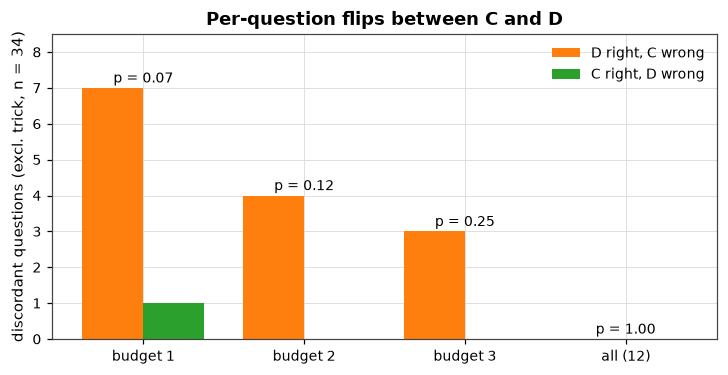

In [5]:
rows = []
for cap in caps:
    m = al.correctness_matrix(answers_by_cap[cap], variants=("C", "D"))
    b = int((m["D"] & ~m["C"]).sum())
    c = int((m["C"] & ~m["D"]).sum())
    rows.append({"budget": cap, "D right / C wrong": b, "C right / D wrong": c, "McNemar p": round(al.mcnemar_exact(b, c), 3)})
disc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.8, 3.6))
x = np.arange(len(disc))
w = 0.38
ax.bar(x - w / 2, disc["D right / C wrong"], w, color=al.VARIANT_COLORS["D"], label="D right, C wrong")
ax.bar(x + w / 2, disc["C right / D wrong"], w, color=al.VARIANT_COLORS["C"], label="C right, D wrong")
for i, r in disc.iterrows():
    ax.text(i, max(r["D right / C wrong"], r["C right / D wrong"]) + 0.15, f"p = {r['McNemar p']:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, ["budget 1", "budget 2", "budget 3", "all (12)"])
ax.set_ylabel("discordant questions (excl. trick, n = 34)")
ax.set_ylim(0, 8.5)
ax.set_title("Per-question flips between C and D")
ax.legend()
al.save_figure(fig, "02_discordant")
disc

> **Reading the chart.** D's advantage is a *superset* of C's: at budgets 3 and 2
> D wins 3-4 questions and loses none; at budget 1 it wins 7 and loses 1
> (q-006, where the dictionary-first sense happened to be right). The exact
> McNemar p-values (0.07-0.25) remind us that with 34 questions a consistent
> +3..7-question shift is *signal, not proof* - the budget curve is the stronger
> evidence because the effect grows monotonically with truncation.

## Where the errors come from (retrieval vs composition)

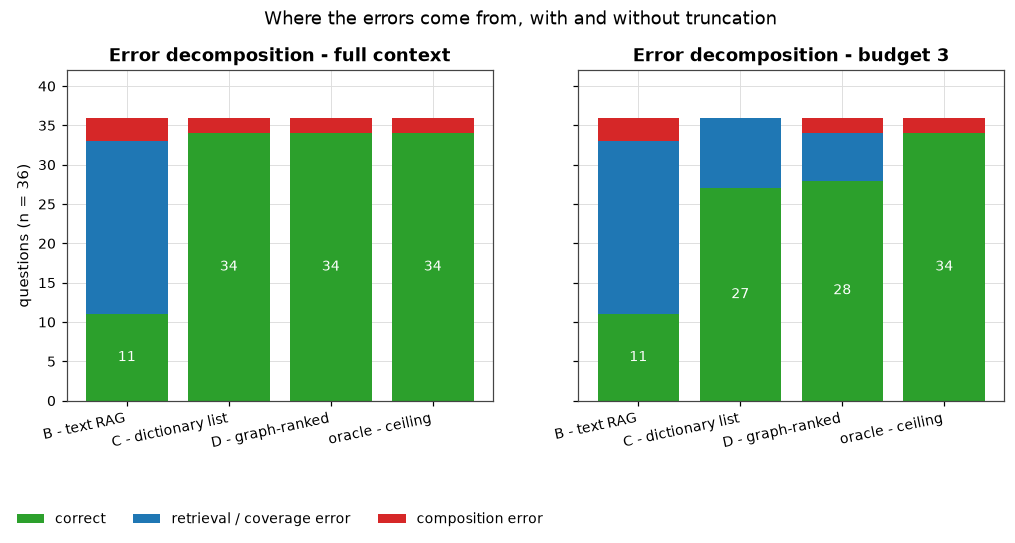

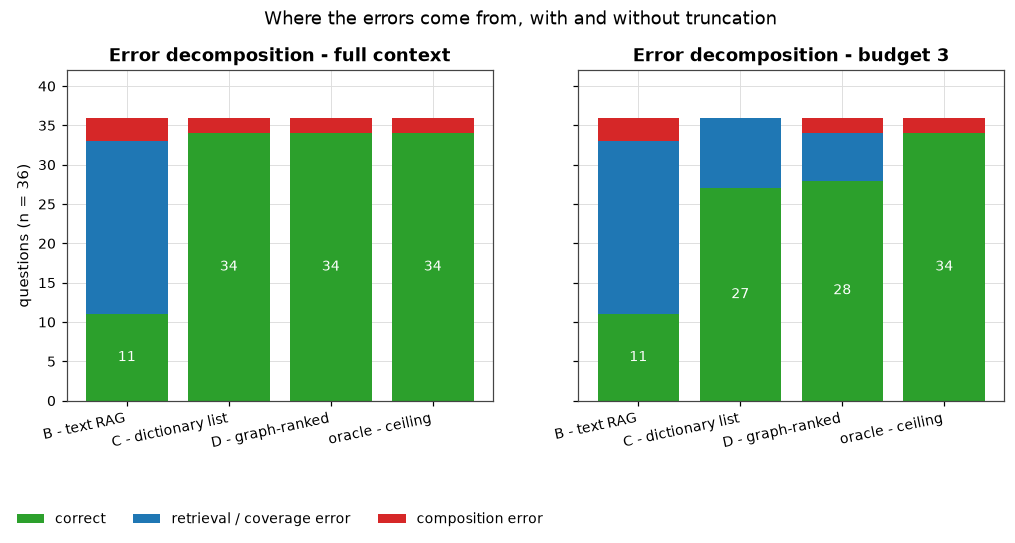

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, cap, label in zip(axes, [12, 3], ["full context", "budget 3"], strict=True):
    df = answers_by_cap[cap]
    variants = ["B", "C", "D", "oracle"]
    correct, retrieval, composition = [], [], []
    for v in variants:
        sub = df[df["variant"] == v]
        comp = int(al.load_metrics(run_of[cap])["variants"][v].get("composition_errors", 0))
        c = int(sub["correct"].sum())
        correct.append(c)
        composition.append(comp)
        retrieval.append(len(sub) - c - comp)
    x = np.arange(len(variants))
    ax.bar(x, correct, color="#2ca02c", label="correct")
    ax.bar(x, retrieval, bottom=correct, color="#1f77b4", label="retrieval / coverage error")
    ax.bar(x, composition, bottom=np.array(correct) + np.array(retrieval), color="#d62728", label="composition error")
    for i in range(len(variants)):
        ax.text(i, correct[i] / 2, str(correct[i]), ha="center", va="center", color="white", fontsize=9)
    ax.set_xticks(x, [al.VARIANT_LABELS[v] for v in variants])
    plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
    ax.set_title(f"Error decomposition - {label}")
    ax.set_ylim(0, 42)
axes[0].set_ylabel("questions (n = 36)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.30), ncol=3, frameon=False)
fig.suptitle("Where the errors come from, with and without truncation", y=1.02)
al.save_figure(fig, "02_error_split")
fig

> **Reading the chart.** At full context, all structured variants' errors are
> just the two flawed `trick` items (composition "errors" that no system can
> avoid). Under truncation, the error type flips to **coverage**: C misses 9
> questions and D misses 6, purely because the gold sense did not fit into the
> budget. B's errors stay retrieval-dominated at every budget.

## The boundary case: when everything fits, C ≡ D

The full-context run is the *boundary* of the whole comparison: if all
candidates fit, ordering cannot matter - and indeed C, D and oracle coincide.
It is worth one look, because it defines when the graph is worthless (and why
its two remaining errors are not about methods):

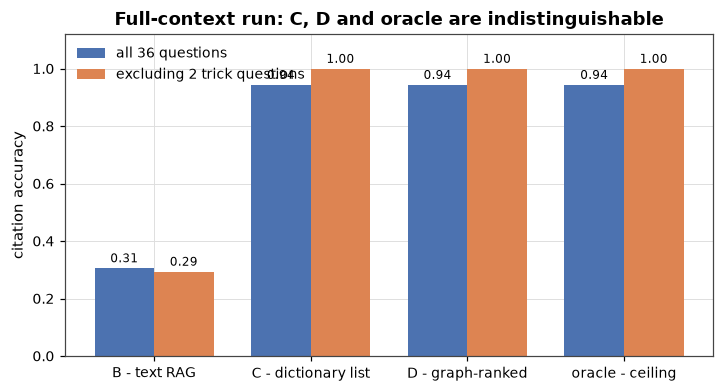

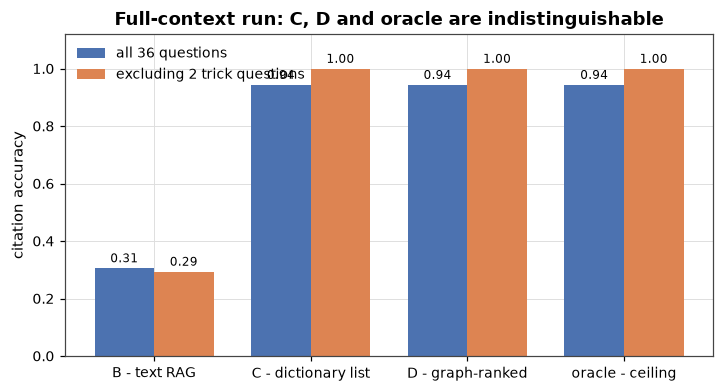

In [7]:
order = ["B", "C", "D", "oracle"]
x = np.arange(len(order))
w = 0.38

fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.bar(x - w / 2, [acc[(acc["cap"] == 12) & (acc["variant"] == v)]["citation_accuracy"].iloc[0] for v in order], w, color="#4c72b0", label="all 36 questions")
ax.bar(x + w / 2, [acc[(acc["cap"] == 12) & (acc["variant"] == v)]["citation_accuracy_excl_trick"].iloc[0] for v in order], w, color="#dd8452", label="excluding 2 trick questions")
for i, v in enumerate(order):
    a = acc[(acc["cap"] == 12) & (acc["variant"] == v)]
    ax.text(i - w / 2, a["citation_accuracy"].iloc[0] + 0.02, f"{a['citation_accuracy'].iloc[0]:.2f}", ha="center", fontsize=8)
    ax.text(i + w / 2, a["citation_accuracy_excl_trick"].iloc[0] + 0.02, f"{a['citation_accuracy_excl_trick'].iloc[0]:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, [al.VARIANT_LABELS[v] for v in order])
ax.set_ylabel("citation accuracy")
ax.set_ylim(0, 1.12)
ax.set_title("Full-context run: C, D and oracle are indistinguishable")
ax.legend(loc="upper left")
al.save_figure(fig, "02_boundary_full_context")
fig

In [8]:
for qid in ["q-005", "q-016"]:
    rows = full[(full["question_id"] == qid) & (full["variant"].isin(["C", "D"]))]
    gold = rows.iloc[0]["gold_sense_id"]
    print("=" * 72)
    print(qid, "| lemma:", rows.iloc[0]["lemma"], "| gold:", gold, "|", senses.loc[gold, "definition"][:70])
    for _, r in rows.iterrows():
        print(f"  {r['variant']}: cited {r['cited_sense_id']}  |  {str(r['answer'])[:95]}")
    shown = rows[rows["variant"] == "C"].iloc[0]["shown_ids"]
    print("  C candidates:", [(s, senses.loc[s, "definition"][:38]) for s in shown[:4]])

q-005 | lemma: vlak | gold: 16258766 | prevozno sredstvo
  C: cited 16254714  |  Vozilo, ki vozi po tirih. v tem stavku gre za vlak, ki vozi proti Mariboru.
  D: cited 16254714  |  Vozilo, ki vozi po tirih in prevaža potnike ali tovor.
  C candidates: [('16254714', 'vozilo na tirih'), ('16258766', 'prevozno sredstvo'), ('16276829', 'o zamujeni priložnosti | če rečemo, da'), ('16276941', 'o burnem dogajanju | hiter in neobvlad')]
q-016 | lemma: zvezda | gold: 16261799 | nebesno telo | nebesno telo, ki služi za orientacijo
  C: cited 16268676  |  Nebesno telo, ki sveti na nočnem nebu.
  D: cited 16268676  |  Nebesno telo, ki sveti na nočnem nebu.
  C candidates: [('16254663', 'komet'), ('16254788', 'o trajnosti pojava ali osebe'), ('16261799', 'nebesno telo | nebesno telo, ki služi '), ('16268676', 'nebesno telo')]


> **What the boundary case teaches.** (1) The graph's value exists *only* under
> truncation - this is the "off switch" of the whole idea, and we measured it.
> (2) The only full-context errors of the structured variants are two flawed
> items: for *vlak*, the candidate list contains the multiword-unit sense
> "vlak smrti"; for *zvezda*, the dictionary has two near-duplicate "nebesno
> telo" senses. Both are flagged `trick` and excluded from headline numbers -
> the ceiling here is set by the **inventory**, not by retrieval or the model.

## Response time

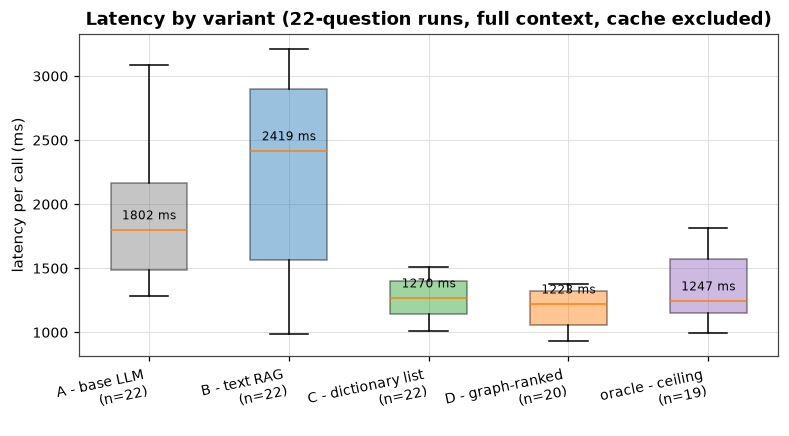

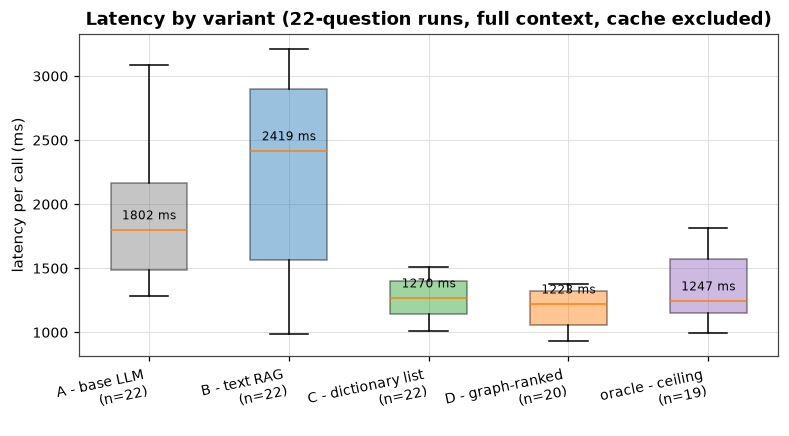

In [9]:
old_runs = al.find_runs()
old_runs = old_runs[(~old_runs["dry_run"]) & (old_runs["n_questions"] == 22)]
lat = pd.concat([al.load_answers(rid) for rid in old_runs["run_id"]], ignore_index=True)
lat = lat[(~lat["cache_hit"]) & lat["latency_ms"].notna()]
variants = ["A", "B", "C", "D", "oracle"]

fig, ax = plt.subplots(figsize=(8.2, 3.8))
data = [lat[lat["variant"] == v]["latency_ms"].to_numpy() for v in variants]
labels = [f"{al.VARIANT_LABELS[v]}\n(n={len(d)})" for v, d in zip(variants, data, strict=True)]
bp = ax.boxplot(data, tick_labels=labels, showfliers=False, patch_artist=True, widths=0.55)
for patch, v in zip(bp["boxes"], variants, strict=True):
    patch.set_facecolor(al.VARIANT_COLORS[v])
    patch.set_alpha(0.45)
for i in range(len(variants)):
    med = float(np.median(data[i]))
    ax.text(i + 1, med + 80, f"{med:.0f} ms", ha="center", fontsize=8)
ax.set_ylabel("latency per call (ms)")
ax.set_title("Latency by variant (22-question runs, full context, cache excluded)")
plt.xticks(rotation=12, ha="right")
al.save_figure(fig, "02_latency")
fig

> **Reading the chart.** All five variants on the same 22-question set with full
> context (D from a follow-up run with identical prompts; n is annotated). B is
> the slowest and widest (retrieval prompt + provider variance); A is slower
> than the structured variants despite having no context, because its free-form
> answers are long. Treat these as operational signals, not a benchmark.

## Variant B in depth: why open semantic search fails

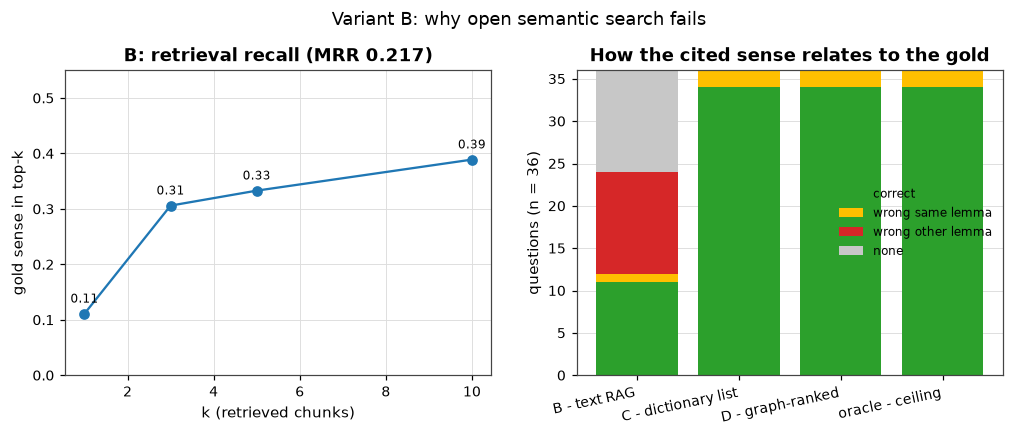

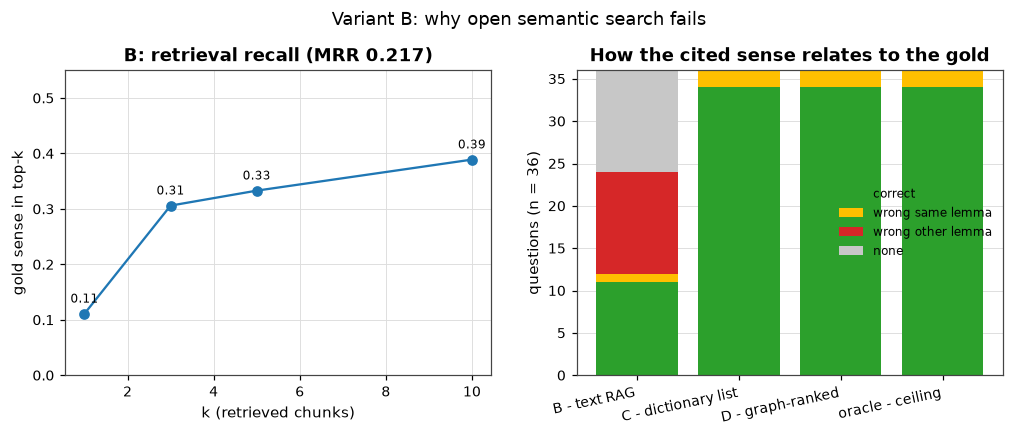

In [10]:
b_metrics = metrics_full["variants"]["B"]
recall = {int(k): v for k, v in b_metrics["recall_at_k"].items()}
tax = b_metrics["error_taxonomy"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
ks = sorted(recall)
ax.plot(ks, [recall[k] for k in ks], "o-", color=al.VARIANT_COLORS["B"])
for k in ks:
    ax.text(k, recall[k] + 0.02, f"{recall[k]:.2f}", ha="center", fontsize=8)
ax.set_xlabel("k (retrieved chunks)")
ax.set_ylabel("gold sense in top-k")
ax.set_ylim(0, 0.55)
ax.set_title(f"B: retrieval recall (MRR {b_metrics['mrr']:.3f})")

ax = axes[1]
cats = ["correct", "wrong_same_lemma", "wrong_other_lemma", "none"]
colors = {"correct": "#2ca02c", "wrong_same_lemma": "#ffbf00", "wrong_other_lemma": "#d62728", "none": "#c7c7c7"}
variants_t = ["B", "C", "D", "oracle"]
bottom = np.zeros(len(variants_t))
for cat in cats:
    vals = np.array([metrics_full["variants"][v]["error_taxonomy"].get(cat, 0) for v in variants_t])
    ax.bar(np.arange(len(variants_t)), vals, bottom=bottom, label=cat.replace("_", " "), color=colors[cat])
    bottom += vals
ax.set_xticks(np.arange(len(variants_t)), [al.VARIANT_LABELS[v] for v in variants_t])
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
ax.set_ylabel("questions (n = 36)")
ax.set_title("How the cited sense relates to the gold")
ax.legend(fontsize=8, loc="center right")

fig.suptitle("Variant B: why open semantic search fails", y=1.03)
al.save_figure(fig, "02_b_deep_dive")
fig

> **Reading the chart.** B's gold sense reaches the top-10 only **39 %** of the
> time (MRR 0.217). Its citation behaviour splits three ways: 11 correct,
> 1 wrong-but-same-lemma, **12 citations of a different lemma** and **12
> refusals** (`SENSE_ID: none`). The retriever's top-1 pick belongs to the wrong
> lemma in **78 %** of calls.

> **Takeaway.** For lemma-specific sense questions, searching the whole
> 131k-sense inventory by embedding similarity is the wrong tool: the first fix
> is *candidate restriction* (which word is this about?), not a better ranker -
> exactly what C and D get for free. (Variant A cannot cite IDs at all; its
> free-text answers are scored in notebook 5.)

## What the head-to-head says

1. **Correctness**: A < B ≪ C ≈ D, and the C-vs-D gap grows as the budget
   shrinks (0.00 → +0.09 → +0.12 → +0.18). All structured variants hit the
   oracle ceiling at full context.
2. **Citations**: B frequently cites the wrong lemma or refuses; C/D/oracle
   cite the right lemma almost always, and their few wrong answers are
   neighbouring senses (notebook 5 breaks this down).
3. **Response time**: structured variants are the fastest; B the slowest; A slow
   because of long free-form answers.
4. **Error split**: B fails at retrieval; structured variants fail only by
   coverage (under truncation) or on flawed items (full context).
5. **The boundary case**: when everything fits, C ≡ D - ordering cannot matter.
   The question "does the graph justify its cost?" therefore becomes
   "**when does the budget bind, and when is there a signal to rank with?**" -
   answered in notebook 3.